# CodeAlpha Task 3 - Data Visualization

## Superstore Sales Analysis

This project transforms raw Superstore sales data into meaningful visualizations
using Python, Pandas, Matplotlib, and Seaborn.

### Objectives

- Explore sales and profit performance.
- Identify trends over time.
- Compare product categories and regions.
- Identify top-performing products.
- Analyze the relationship between sales and profit.
- Create visualizations that support business decision-making.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Superstore dataset
df = pd.read_csv(
    r"D:\CodeAlpha_Internship\CodeAlpha_Visualization\data\superstore.csv"
)

# Display basic information
print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [5]:
# Convert date columns to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

# Check data types
print("Data types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Data types:
Row ID                   object
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code             float64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                float64
Discount                float64
Profit                  float64
dtype: object

Missing values:
15325

Duplicate rows: 504


In [6]:
# Check missing values by column
missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values[missing_values > 0])

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Display duplicate rows
print("\nSample duplicate rows:")
df[df.duplicated()].head()

Missing values by column:
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

Number of duplicate rows: 504

Sample duplicate rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10001,Yes,CA-2015-100762,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10006,Yes,CA-2015-102652,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10007,Yes,CA-2015-102652,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# Find rows with missing Order Date
missing_date_rows = df[df["Order Date"].isna()]

print("Number of rows with missing Order Date:", len(missing_date_rows))

print("\nFirst 10 incomplete rows:")
display(missing_date_rows.head(10))

Number of rows with missing Order Date: 806

First 10 incomplete rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9994,Person,Region,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000,Yes,CA-2015-100762,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# Inspect rows around the point where the dataset changes
print(df.iloc[9988:10010][
    ["Row ID", "Order ID", "Order Date", "Ship Date",
     "Customer Name", "Category", "Sales", "Profit"]
].to_string())

                  Row ID        Order ID Order Date  Ship Date     Customer Name         Category    Sales   Profit
9988                9989  CA-2018-163629 2018-11-17 2018-11-21      Ruben Ausman       Technology  206.100  55.6470
9989                9990  CA-2015-110422 2015-01-21 2015-01-23  Tom Boeckenhauer        Furniture   25.248   4.1028
9990                9991  CA-2018-121258 2018-02-26 2018-03-03       Dave Brooks        Furniture   91.960  15.6332
9991                9992  CA-2018-121258 2018-02-26 2018-03-03       Dave Brooks       Technology  258.576  19.3932
9992                9993  CA-2018-121258 2018-02-26 2018-03-03       Dave Brooks  Office Supplies   29.600  13.3200
9993                9994  CA-2018-119914 2018-05-04 2018-05-09      Chris Cortes  Office Supplies  243.160  72.9480
9994              Person          Region        NaT        NaT               NaN              NaN      NaN      NaN
9995       Anna Andreadi            West        NaT        NaT          

In [9]:
# Keep only the valid Superstore transaction records
df = df.iloc[:9994].copy()

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Reset the index
df.reset_index(drop=True, inplace=True)

print("Dataset cleaned successfully!")
print("Shape after cleaning:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum().sum())

print("\nDuplicate rows after cleaning:")
print(df.duplicated().sum())

Dataset cleaned successfully!
Shape after cleaning: (9994, 21)

Missing values after cleaning:
11

Duplicate rows after cleaning:
0


In [10]:
# Check remaining missing values by column
remaining_missing = df.isnull().sum()

print("Remaining missing values:")
print(remaining_missing[remaining_missing > 0])

# Display rows containing missing values
print("\nRows containing missing values:")
display(df[df.isnull().any(axis=1)])

Remaining missing values:
Postal Code    11
dtype: int64

Rows containing missing values:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
2234,2235,CA-2018-104066,2018-12-05,2018-12-10,Standard Class,QJ-19255,Quincy Jones,Corporate,United States,Burlington,...,NaN,East,TEC-AC-10001013,Technology,Accessories,Logitech ClearChat Comfort/USB Headset H390,205.03,7.0,0.0,67.6599
5274,5275,CA-2016-162887,2016-11-07,2016-11-09,Second Class,SV-20785,Stewart Visinsky,Consumer,United States,Burlington,...,NaN,East,FUR-CH-10000595,Furniture,Chairs,Safco Contoured Stacking Chairs,715.20,3.0,0.0,178.8000
8798,8799,US-2017-150140,2017-04-06,2017-04-10,Standard Class,VM-21685,Valerie Mitchum,Home Office,United States,Burlington,...,NaN,East,TEC-PH-10002555,Technology,Phones,Nortel Meridian M5316 Digital phone,1294.75,5.0,0.0,336.6350
9146,9147,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,...,NaN,East,TEC-AC-10002926,Technology,Accessories,Logitech Wireless Marathon Mouse M705,99.98,2.0,0.0,42.9914
9147,9148,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,...,NaN,East,OFF-AR-10003477,Office Supplies,Art,4009 Highlighters,8.04,6.0,0.0,2.7336
9148,9149,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,...,NaN,East,OFF-ST-10001526,Office Supplies,Storage,Iceberg Mobile Mega Data/Printer Cart,1564.29,13.0,0.0,406.7154
9386,9387,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,...,NaN,East,OFF-PA-10000157,Office Supplies,Paper,Xerox 191,79.92,4.0,0.0,37.5624
9387,9388,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,...,NaN,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,12.28,1.0,0.0,5.7716
9388,9389,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,...,NaN,East,OFF-AP-10000828,Office Supplies,Appliances,Avanti 4.4 Cu. Ft. Refrigerator,542.94,3.0,0.0,152.0232
9389,9390,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,...,NaN,East,OFF-EN-10001509,Office Supplies,Envelopes,Poly String Tie Envelopes,2.04,1.0,0.0,0.9588


In [11]:
# Postal Code is not required for our visualization analysis.
# Keep the valid transactions and allow missing postal codes.

print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDate range:")
print("From:", df["Order Date"].min().date())
print("To:", df["Order Date"].max().date())

Final dataset shape: (9994, 21)

Missing values:
Postal Code    11
dtype: int64

Duplicate rows: 0

Date range:
From: 2015-01-03
To: 2018-12-30


In [12]:
# Calculate total sales by category
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

print("Total Sales by Category:")
print(category_sales)

Total Sales by Category:
Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


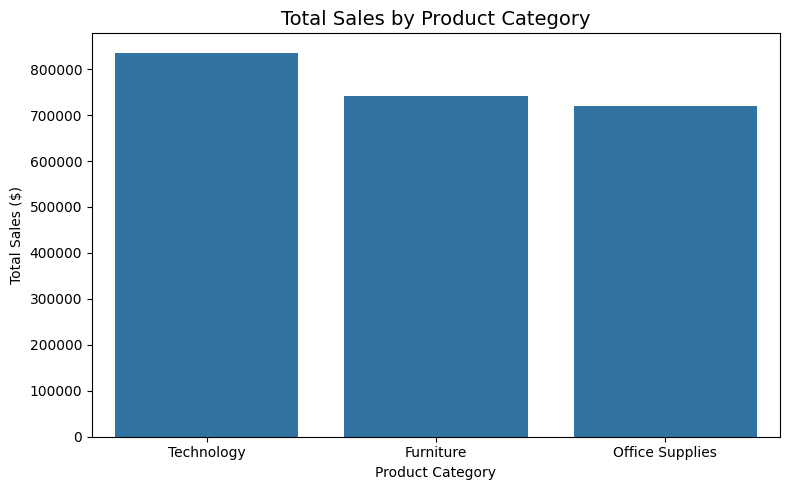

Chart saved successfully to:
D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots\sales_by_category.png


In [14]:
from pathlib import Path

# Create the screenshots folder if it doesn't already exist
screenshots_path = Path(
    r"D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots"
)

screenshots_path.mkdir(parents=True, exist_ok=True)

# Create Sales by Category visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title("Total Sales by Product Category", fontsize=14)
plt.xlabel("Product Category")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)

plt.tight_layout()

# Save visualization
chart_path = screenshots_path / "sales_by_category.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully to:")
print(chart_path)

In [15]:
# Calculate monthly sales
monthly_sales = (
    df.set_index("Order Date")
      .resample("ME")["Sales"]
      .sum()
)

print("Monthly Sales:")
print(monthly_sales.head())

Monthly Sales:
Order Date
2015-01-31    14236.895
2015-02-28     4519.892
2015-03-31    55691.009
2015-04-30    28295.345
2015-05-31    23648.287
Freq: ME, Name: Sales, dtype: float64


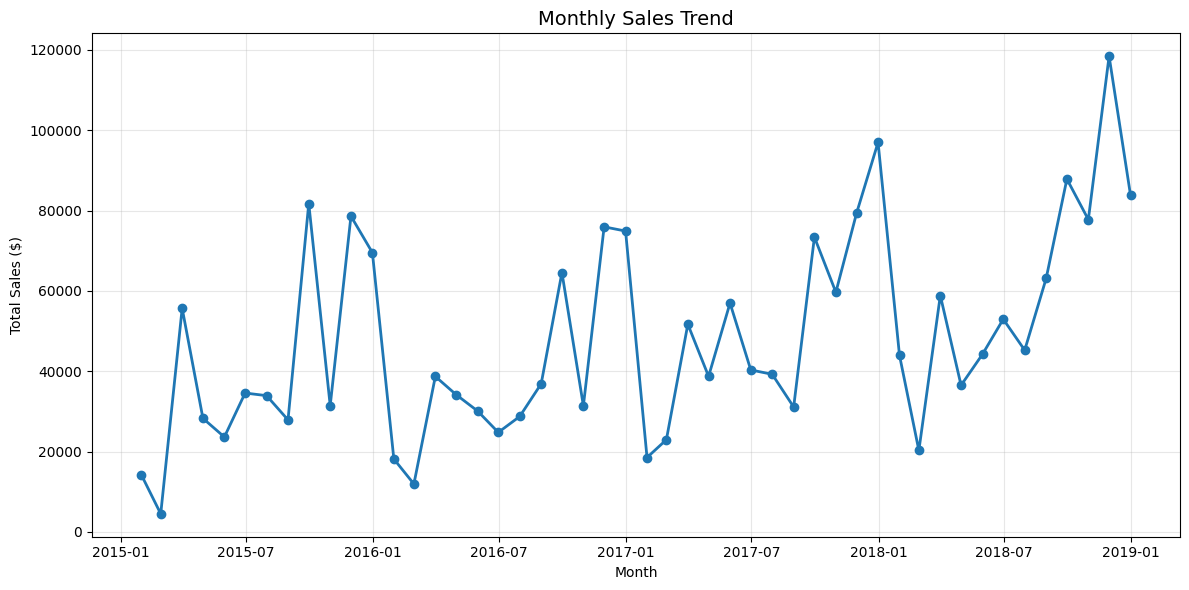

Chart saved successfully to:
D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots\monthly_sales_trend.png


In [16]:
# Create Monthly Sales Trend visualization

from pathlib import Path

screenshots_path = Path(
    r"D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots"
)

screenshots_path.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save visualization
chart_path = screenshots_path / "monthly_sales_trend.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully to:")
print(chart_path)

In [17]:
# Calculate total sales by region
region_sales = (
    df.groupby("Region")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

print("Total Sales by Region:")
print(region_sales)

Total Sales by Region:
Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


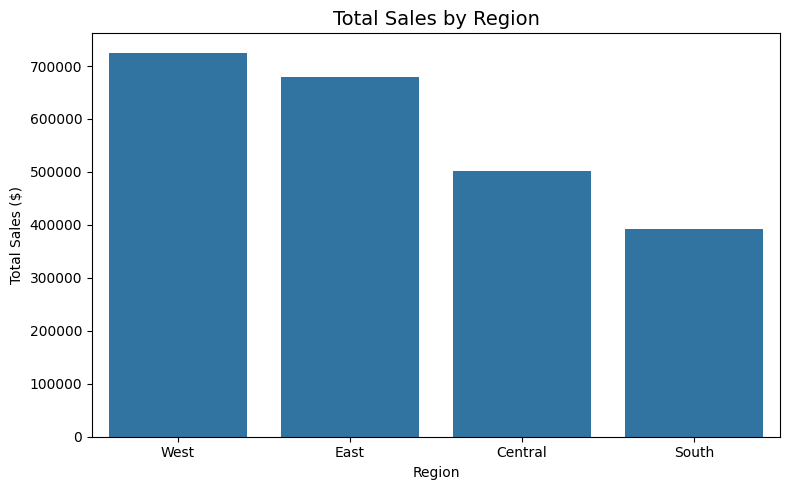

Chart saved successfully to:
D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots\sales_by_region.png


In [18]:
# Create Sales by Region visualization

from pathlib import Path

screenshots_path = Path(
    r"D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots"
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=region_sales.index,
    y=region_sales.values
)

plt.title("Total Sales by Region", fontsize=14)
plt.xlabel("Region")
plt.ylabel("Total Sales ($)")

plt.tight_layout()

# Save visualization
chart_path = screenshots_path / "sales_by_region.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully to:")
print(chart_path)

In [19]:
# Calculate total sales by product
product_sales = (
    df.groupby("Product Name")["Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print("Top 10 Products by Sales:")
print(product_sales)

Top 10 Products by Sales:
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


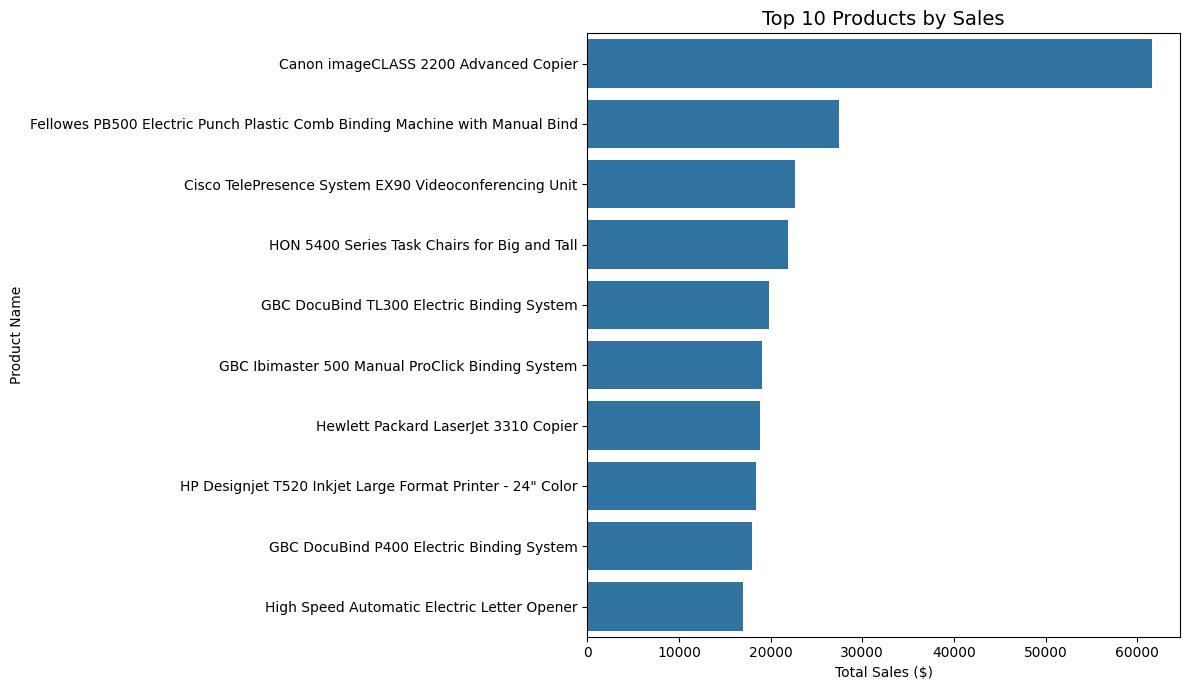

Chart saved successfully to:
D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots\top_10_products_sales.png


In [20]:


from pathlib import Path

screenshots_path = Path(
    r"D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots"
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=product_sales.values,
    y=product_sales.index
)

plt.title("Top 10 Products by Sales", fontsize=14)
plt.xlabel("Total Sales ($)")
plt.ylabel("Product Name")

plt.tight_layout()

# Save visualization
chart_path = screenshots_path / "top_10_products_sales.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully to:")
print(chart_path)

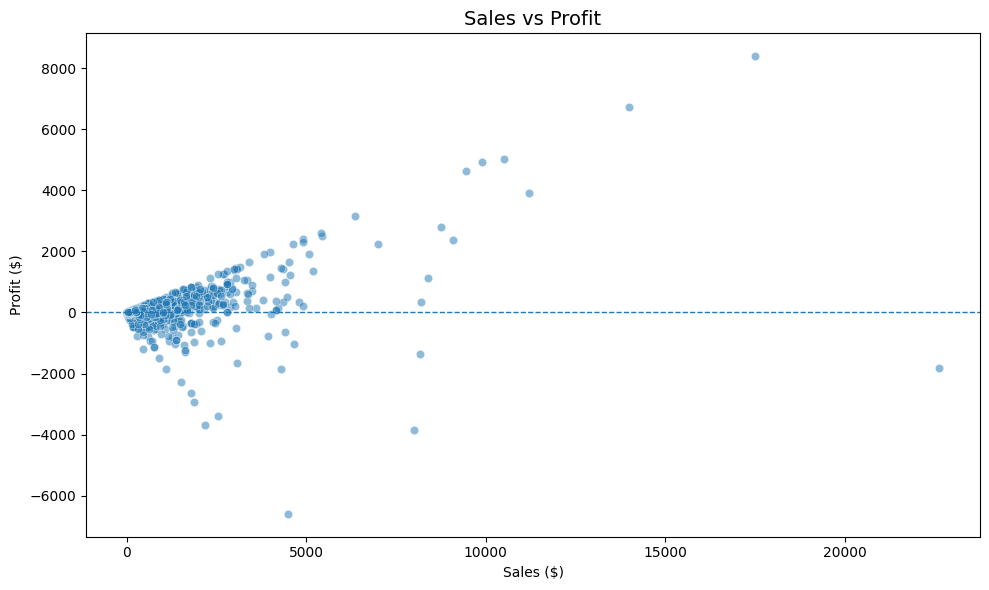

Chart saved successfully to:
D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots\sales_vs_profit.png


In [21]:
# Create Sales vs Profit scatter plot

from pathlib import Path

screenshots_path = Path(
    r"D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots"
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit",
    alpha=0.5
)

plt.title("Sales vs Profit", fontsize=14)
plt.xlabel("Sales ($)")
plt.ylabel("Profit ($)")
plt.axhline(0, linestyle="--", linewidth=1)

plt.tight_layout()

# Save visualization
chart_path = screenshots_path / "sales_vs_profit.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully to:")
print(chart_path)

In [22]:
# Calculate total profit by category
category_profit = (
    df.groupby("Category")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

print("Total Profit by Category:")
print(category_profit)

Total Profit by Category:
Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


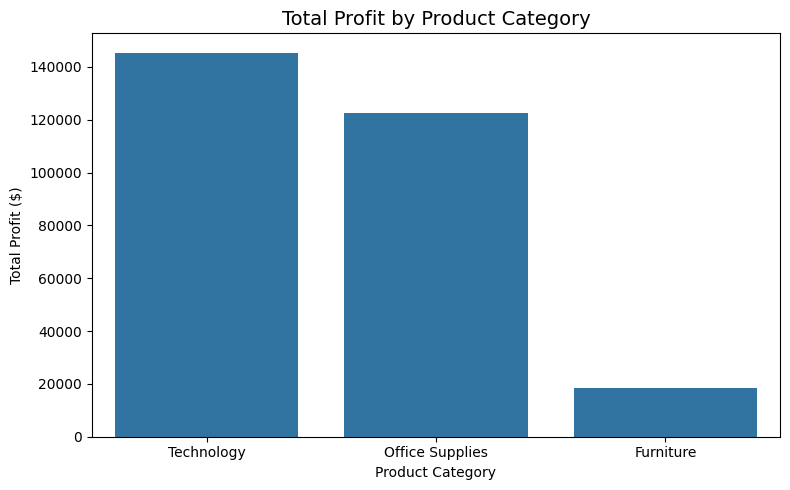

Chart saved successfully to:
D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots\profit_by_category.png


In [23]:
# Create Profit by Category visualization

from pathlib import Path

screenshots_path = Path(
    r"D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots"
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_profit.index,
    y=category_profit.values
)

plt.title("Total Profit by Product Category", fontsize=14)
plt.xlabel("Product Category")
plt.ylabel("Total Profit ($)")

plt.tight_layout()

# Save visualization
chart_path = screenshots_path / "profit_by_category.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully to:")
print(chart_path)

In [24]:
# Calculate sales and profit by sub-category

subcategory_performance = (
    df.groupby("Sub-Category")[["Sales", "Profit"]]
      .sum()
      .sort_values("Sales", ascending=False)
)

print("Sales and Profit by Sub-Category:")
print(subcategory_performance)

Sales and Profit by Sub-Category:
                    Sales      Profit
Sub-Category                         
Phones        330007.0540  44515.7306
Chairs        328449.1030  26590.1663
Storage       223843.6080  21278.8264
Tables        206965.5320 -17725.4811
Binders       203412.7330  30221.7633
Machines      189238.6310   3384.7569
Accessories   167380.3180  41936.6357
Copiers       149528.0300  55617.8249
Bookcases     114879.9963  -3472.5560
Appliances    107532.1610  18138.0054
Furnishings    91705.1640  13059.1436
Paper          78479.2060  34053.5693
Supplies       46673.5380  -1189.0995
Art            27118.7920   6527.7870
Envelopes      16476.4020   6964.1767
Labels         12486.3120   5546.2540
Fasteners       3024.2800    949.5182


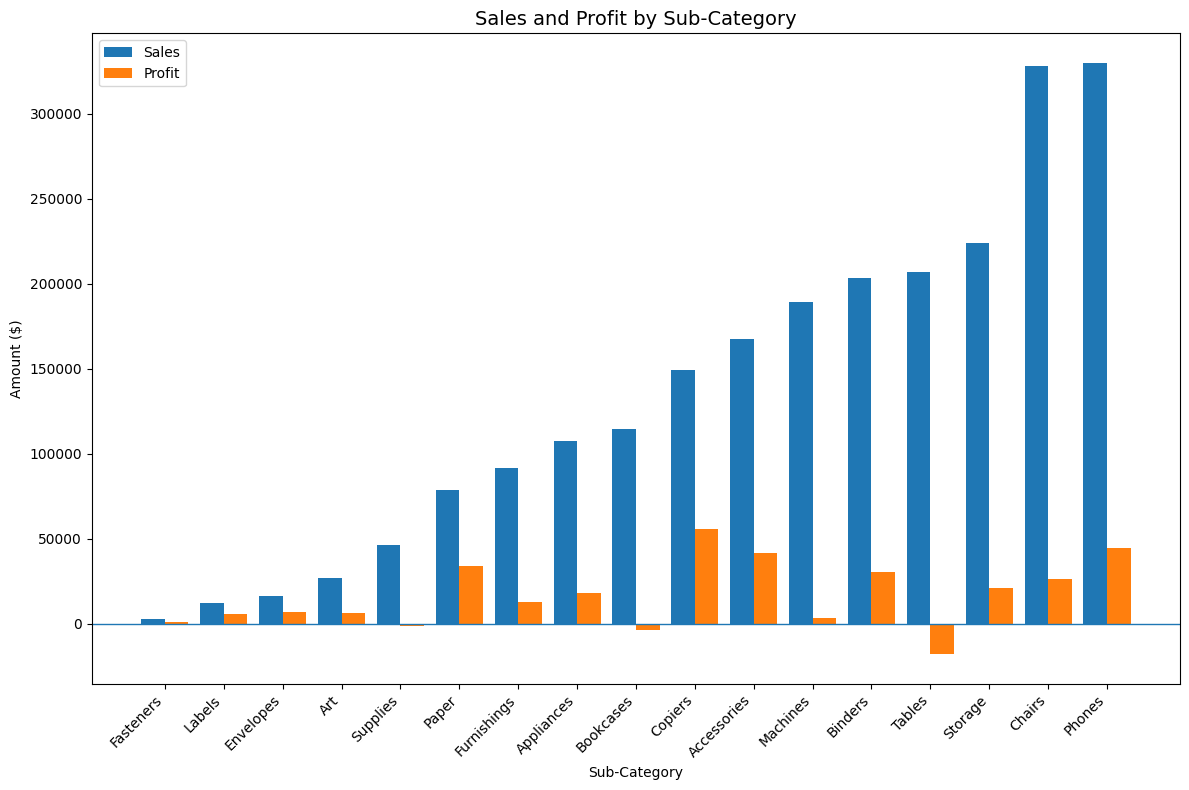

Chart saved successfully to:
D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots\sales_profit_by_subcategory.png


In [25]:
# Create Sales and Profit by Sub-Category visualization

from pathlib import Path

screenshots_path = Path(
    r"D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots"
)

# Sort by sales for better readability
subcategory_chart = subcategory_performance.sort_values(
    "Sales",
    ascending=True
)

plt.figure(figsize=(12, 8))

x = np.arange(len(subcategory_chart.index))
width = 0.4

plt.bar(
    x - width / 2,
    subcategory_chart["Sales"],
    width,
    label="Sales"
)

plt.bar(
    x + width / 2,
    subcategory_chart["Profit"],
    width,
    label="Profit"
)

plt.axhline(0, linewidth=1)

plt.title("Sales and Profit by Sub-Category", fontsize=14)
plt.xlabel("Sub-Category")
plt.ylabel("Amount ($)")
plt.xticks(
    x,
    subcategory_chart.index,
    rotation=45,
    ha="right"
)

plt.legend()
plt.tight_layout()

# Save visualization
chart_path = screenshots_path / "sales_profit_by_subcategory.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully to:")
print(chart_path)

In [26]:
# Calculate total sales by customer segment

segment_sales = (
    df.groupby("Segment")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

print("Total Sales by Customer Segment:")
print(segment_sales)

Total Sales by Customer Segment:
Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64


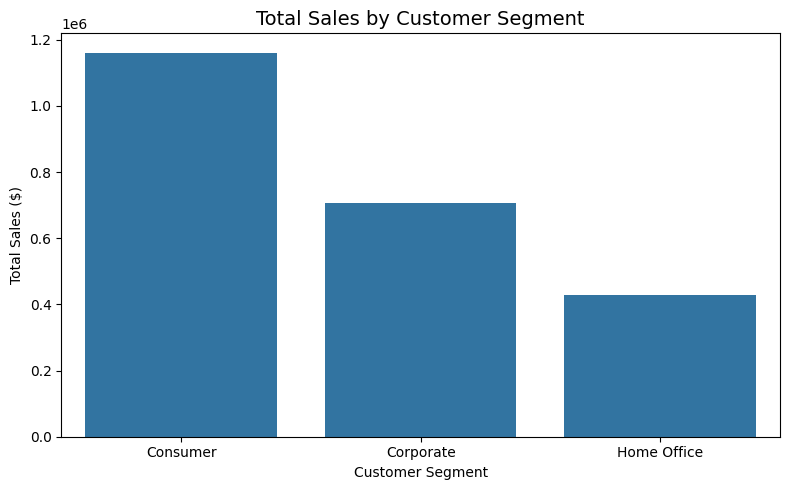

Chart saved successfully to:
D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots\sales_by_customer_segment.png


In [27]:
# Create Sales by Customer Segment visualization

from pathlib import Path

screenshots_path = Path(
    r"D:\CodeAlpha_Internship\CodeAlpha_Visualization\screenshots"
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=segment_sales.index,
    y=segment_sales.values
)

plt.title("Total Sales by Customer Segment", fontsize=14)
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales ($)")

plt.tight_layout()

# Save visualization
chart_path = screenshots_path / "sales_by_customer_segment.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully to:")
print(chart_path)

## Business Insights and Data Storytelling

### Key Business Insights

- **Technology is the most profitable category:** Technology generated approximately **$145,455** in total profit, making it the strongest category in terms of profitability.

- **Furniture has relatively low profitability:** Although Furniture generates significant sales, its total profit is only approximately **$18,451**, indicating that this category may require better pricing or cost management.

- **West is the strongest region by sales:** The West region generated approximately **$725,458** in sales, making it the highest-performing region.

- **South has the lowest sales:** The South region generated approximately **$391,722** in sales, suggesting an opportunity for improving regional sales performance.

- **Consumer customers contribute the most sales:** The Consumer segment generated approximately **$1.16 million** in sales, followed by Corporate and Home Office customers.

- **Canon imageCLASS 2200 Advanced Copier is the top-selling product:** It generated approximately **$61,600** in sales, making it the highest-selling individual product in the dataset.

- **Some sub-categories generate sales but produce losses:** Tables, Bookcases, and Supplies recorded negative total profits despite generating sales. These products may require closer examination of pricing, discounts, and costs.

- **Higher sales do not always guarantee higher profit:** The Sales vs Profit visualization shows that some transactions with relatively high sales can still produce low or negative profits.

### Business Recommendations

Based on the analysis and visualizations, the following recommendations can be made:

1. **Focus on profitable categories:** The business should continue investing in Technology products because this category generates the highest overall profit.

2. **Review Furniture performance:** Furniture has comparatively low profitability. The business should investigate product costs, pricing strategies, and discount levels in this category.

3. **Investigate loss-making sub-categories:** Tables, Bookcases, and Supplies generate sales but result in negative profit. These products should be reviewed to identify the causes of losses.

4. **Strengthen the South region:** Since the South region has the lowest sales, targeted promotions, improved product availability, and regional marketing strategies could help increase sales.

5. **Leverage the Consumer segment:** Since Consumer customers generate the highest sales, the business can focus on customer retention, personalized offers, and targeted marketing for this segment.

6. **Promote high-performing products:** Products with consistently high sales should receive appropriate inventory planning and promotional support to maintain their performance.

7. **Balance sales and profitability:** Business decisions should consider both sales and profit rather than focusing only on revenue. High sales with low or negative profit may indicate pricing or discount-related problems.

## Conclusion

This data visualization project analyzed the Sample Superstore dataset to identify important patterns in sales, profitability, customer segments, regions, products, and sub-categories.

Eight visualizations were created using Python libraries such as **Pandas, Matplotlib, and Seaborn**. The analysis showed that Technology is the most profitable product category, the West region has the highest sales, and Consumer customers contribute the largest share of sales. The analysis also identified several sub-categories that generate sales but result in negative profits.

The visualizations helped transform raw transactional data into clear and meaningful business insights. These insights can support decisions related to product performance, regional strategies, customer targeting, pricing, and profitability.

Overall, the project demonstrates how data visualization can be used to communicate patterns effectively and support data-driven business decision-making.